# Fisheye Visual Odometry

Implement a visual odometry pipeline for fisheye drone footage that tracks features with Lucas–Kanade flow and recovers a relative camera trajectory.

This notebook only provides **data paths** and **trajectory evaluation**. The pipeline itself is up to you.

**Deliverables** (all in this notebook):
- Recovered relative trajectory, compared against GT with the evaluation cells below
- All code cells run and plots rendered
- Overlay video
- Summary markdown cell at the end: implementation choices, parameter tuning, observed trajectory quality

In [11]:
from pathlib import Path
from pose_helpers import align_similarity, compute_path_length, load_and_prepare_data
import pandas as pd
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

from pose_helpers import (
    TrajectoryResult,
    TrajectoryVideoWriter,
    analyze_trajectory,
    draw_tracks,
    plot_trajectory,
    write_video_with_trajectory,
)

plt.rcParams["figure.figsize"] = (14, 6)
plt.rcParams["font.size"] = 11

In [12]:
# --- Data paths ---
ROOT = Path("./")
DATA_ROOT = Path("./flight")
VIDEO_PATH = DATA_ROOT / "recording.mp4"
CALIBRATION_PATH = ROOT / "calibration-params.json"
GT_PATH = ROOT / "./flight_trajectory_coordinates.csv"

# --- Outputs ---
OVERLAY_VIDEO_PATH = Path("tracks_overlay.mp4")              # written by your pipeline: frames with your tracked points
TRAJECTORY_VIDEO_PATH = Path("tracks_with_trajectory.mp4")   # written by the evaluation: your overlay + trajectory plot

for p in (VIDEO_PATH, CALIBRATION_PATH, GT_PATH):
    if not p.exists():
        raise FileNotFoundError(p)

print(f"Video       : {VIDEO_PATH}")
print(f"Calibration : {CALIBRATION_PATH}")
print(f"Ground truth: {GT_PATH}")

Video       : flight/recording.mp4
Calibration : calibration-params.json
Ground truth: flight_trajectory_coordinates.csv


## Your pipeline

Add as many cells as you need. The evaluation below expects two things.

**1. A `traj_result: TrajectoryResult`** with:

| Field | Shape | Meaning |
| :-- | :-- | :-- |
| `positions` | `(N + 1, ≥2)` array | Row 0 is the starting pose; row `i + 1` is the pose at `frame_indices[i]`. Only X and Y are evaluated. |
| `frame_indices` | `N` ints | Absolute frame index in `recording.mp4` of each recovered pose (used to match GT rows). |
| `inliers` | `N` ints | Inlier count of the motion estimate for each recovered pose. |
| `timestamps` | `N` floats | Time of each recovered pose, in seconds. |

**2. An overlay video at `OVERLAY_VIDEO_PATH`** with one frame per frame of `recording.mp4`, in the same order (frame `k` of the overlay = frame `k` of the recording). `write_video_with_trajectory` seeks into it by `frame_indices`. `TrajectoryVideoWriter` and `draw_tracks` from `pose_helpers` can do this for you.

### Step 1: Feature tracking

1. Load the fisheye (Kannala–Brandt) calibration into `K` and `D`.
2. Detect Shi–Tomasi corners on a grid inside the fisheye image circle, so points are spread over the whole view.
3. Track them frame to frame with pyramidal Lucas–Kanade and a forward–backward consistency check. Drop lost tracks and top up with new corners when too few remain.
4. Draw the tracks on a few frames as a sanity check.

**Hand-off:** `track_pairs`, a list with one entry per pair of neighbouring frames `(k-1, k)`:

| Key | Type | Meaning |
| :-- | :-- | :-- |
| `prev_idx`, `curr_idx` | int | frame indices `k-1`, `k` |
| `timestamp` | float | time of frame `k`, in seconds |
| `pts_prev` | `(N, 2)` float32 | pixel positions in frame `k-1` |
| `pts_curr` | `(N, 2)` float32 | the same points in frame `k` |
| `track_ids` | `(N,)` int | ID of each track, stable across frames |

`undistort_to_normalized(pts)` converts pixels into undistorted normalized camera coordinates for the pose step.

# Fisheye calibration + corner tracking

In [13]:
import json
from collections import deque
from tqdm.auto import tqdm

with open(CALIBRATION_PATH) as f:
    cam = json.load(f)["cameras"][0]

assert cam["model"] == "kannala-brandt4", f"Unexpected camera model: {cam['model']}"

K = np.array(
    [
        [cam["focalLengthX"], 0.0, cam["principalPointX"]],
        [0.0, cam["focalLengthY"], cam["principalPointY"]],
        [0.0, 0.0, 1.0],
    ],
    dtype=np.float64,
)
D = np.array(cam["distortionCoefficients"], dtype=np.float64).reshape(4, 1)
IMG_W, IMG_H = cam["imageWidth"], cam["imageHeight"]


def undistort_to_normalized(pts: np.ndarray) -> np.ndarray:
    """Distorted pixel coords (N, 2) -> undistorted normalized camera coords (N, 2), i.e. focal length 1."""
    pts = np.asarray(pts, dtype=np.float64).reshape(-1, 1, 2)
    return cv.fisheye.undistortPoints(pts, K, D).reshape(-1, 2)


print("K =\n", K)
print("D =", D.ravel())
print(f"Image size: {IMG_W}x{IMG_H}")

K =
 [[5.90067946e+02 0.00000000e+00 1.01506609e+03]
 [0.00000000e+00 5.89524807e+02 5.71356338e+02]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]
D = [-0.03678765  0.00404803 -0.00777366  0.00206872]
Image size: 1920x1080


In [14]:
# --- Tracking parameters (all in one place) ---
GRID = (8, 5)              # (cols, rows) of detection cells; keeps features spread over the image
MAX_PER_CELL = 15          # target number of tracked points per cell
MIN_PER_CELL = 3           # top up a cell once it falls below this...
MIN_TRACKS = 300           # ...or once the total falls below this

GFTT_PARAMS = dict(qualityLevel=0.01, minDistance=15, blockSize=7)
LK_PARAMS = dict(
    winSize=(21, 21),
    maxLevel=4,
    criteria=(cv.TERM_CRITERIA_EPS | cv.TERM_CRITERIA_COUNT, 30, 0.01),
)
FB_THRESH = 1.0            # max forward-backward error [px]
CIRCLE_MARGIN = 20         # px kept away from the fisheye image-circle edge
TRAIL_LEN = 15             # trail length (frames) drawn in the snapshots
SNAPSHOT_FRAMES = [50, 900, 1800, 2700, 3500]

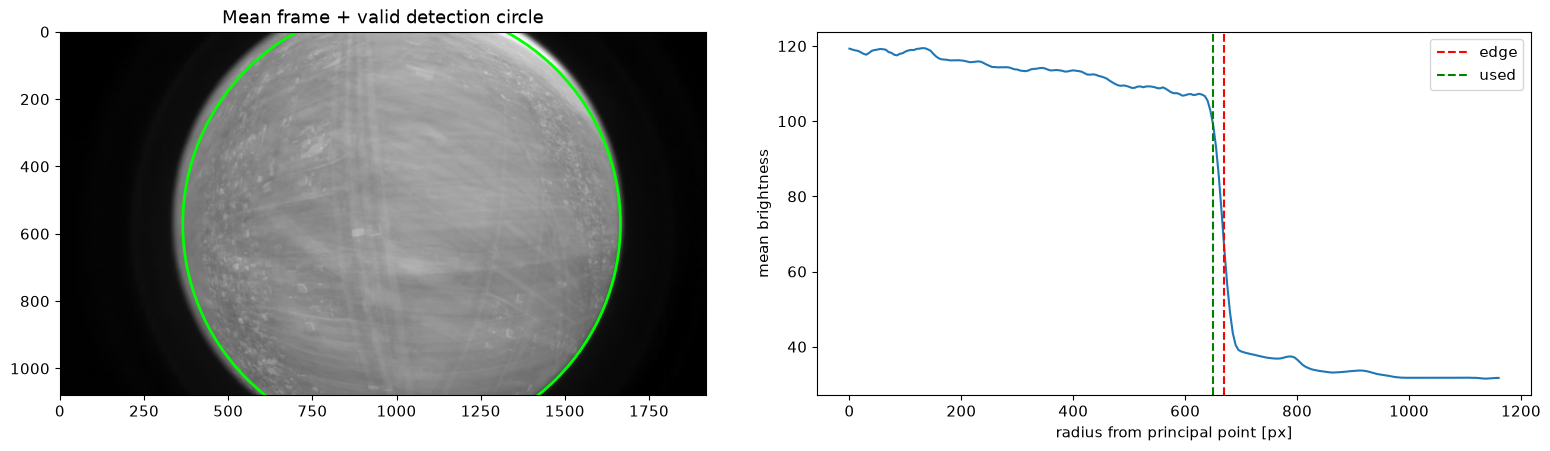

In [15]:
cap = cv.VideoCapture(str(VIDEO_PATH))
n_frames_total = int(cap.get(cv.CAP_PROP_FRAME_COUNT))
mean_img = np.zeros((IMG_H, IMG_W), np.float64)
sample_idx = np.linspace(0, n_frames_total - 1, 10).astype(int)

for i in sample_idx:
    cap.set(cv.CAP_PROP_POS_FRAMES, int(i))
    ok, frame = cap.read()
    assert ok, f"Cannot read frame {i}"
    mean_img += cv.cvtColor(frame, cv.COLOR_BGR2GRAY)
mean_img /= len(sample_idx)
cap.release()

cx, cy = K[0, 2], K[1, 2]
yy, xx = np.mgrid[:IMG_H, :IMG_W]

radius_map = np.hypot(xx - cx, yy - cy)
radii = np.arange(0, int(radius_map.max()), 5)
ring_mean = np.array([mean_img[(radius_map >= r) & (radius_map < r + 5)].mean() for r in radii])

inside, outside = np.median(ring_mean[: len(ring_mean) // 3]), ring_mean[-1]
edge_radius = radii[np.argmax(ring_mean < (inside + outside) / 2)]
valid_radius = edge_radius - CIRCLE_MARGIN

valid_mask = (radius_map < valid_radius).astype(np.uint8) * 255

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
axes[0].imshow(mean_img, cmap="gray")
axes[0].add_patch(plt.Circle((cx, cy), valid_radius, fill=False, color="lime", lw=2))
axes[0].set_title("Mean frame + valid detection circle")
axes[1].plot(radii, ring_mean)
axes[1].axvline(edge_radius, color="r", ls="--", label="edge")
axes[1].axvline(valid_radius, color="g", ls="--", label="used")
axes[1].set_xlabel("radius from principal point [px]")
axes[1].set_ylabel("mean brightness")
axes[1].legend()
plt.tight_layout()
plt.show()

In [16]:

cell_w = IMG_W / GRID[0]
cell_h = IMG_H / GRID[1]


def cell_index(pts: np.ndarray) -> np.ndarray:
    """Flat grid-cell index for each (x, y) point."""
    cx_ = np.clip((pts[:, 0] // cell_w).astype(int), 0, GRID[0] - 1)
    cy_ = np.clip((pts[:, 1] // cell_h).astype(int), 0, GRID[1] - 1)
    return cy_ * GRID[0] + cx_

cell_valid_frac = np.array(
    [
        valid_mask[int(r * cell_h): int((r + 1) * cell_h), int(c * cell_w): int((c + 1) * cell_w)].mean() / 255
        for r in range(GRID[1])
        for c in range(GRID[0])
    ]
)
ACTIVE_CELLS = cell_valid_frac > 0.05

CELL_TARGET = np.ceil(MAX_PER_CELL * cell_valid_frac).astype(int)

def needs_topup(pts: np.ndarray) -> bool:
    if len(pts) < MIN_TRACKS:
        return True
    counts = np.bincount(cell_index(pts), minlength=GRID[0] * GRID[1])
    low = counts < np.minimum(MIN_PER_CELL, CELL_TARGET)
    return bool(np.any(low & ACTIVE_CELLS))


def detect_features(gray: np.ndarray, existing_pts: np.ndarray) -> np.ndarray:
    """Add Shi-Tomasi corners cell by cell, filling each grid cell up to its target count.

    New corners are kept at least minDistance away from already-tracked points.
    Returns only the NEW points, shape (M, 2) float32.
    """
    mask = valid_mask.copy()
    min_dist = GFTT_PARAMS["minDistance"]
    for x, y in existing_pts:
        cv.circle(mask, (int(round(x)), int(round(y))), min_dist, 0, -1)

    counts = (
        np.bincount(cell_index(existing_pts), minlength=GRID[0] * GRID[1])
        if len(existing_pts)
        else np.zeros(GRID[0] * GRID[1], int)
    )
    new_pts = []
    for r in range(GRID[1]):
        for c in range(GRID[0]):
            ci = r * GRID[0] + c
            want = CELL_TARGET[ci] - counts[ci]
            if not ACTIVE_CELLS[ci] or want <= 0:
                continue
            x0, x1 = int(c * cell_w), int((c + 1) * cell_w)
            y0, y1 = int(r * cell_h), int((r + 1) * cell_h)
            corners = cv.goodFeaturesToTrack(
                gray[y0:y1, x0:x1], maxCorners=int(want), mask=mask[y0:y1, x0:x1], **GFTT_PARAMS
            )
            if corners is not None:
                new_pts.append(corners.reshape(-1, 2) + (x0, y0))
    if not new_pts:
        return np.empty((0, 2), np.float32)
    return np.concatenate(new_pts).astype(np.float32)


def track_lk(prev_gray: np.ndarray, curr_gray: np.ndarray, prev_pts: np.ndarray):
    """Pyramidal LK with forward-backward check.

    Returns (p1, keep): p1 (N, 2) tracked positions, keep (N,) bool of reliable tracks.
    """
    if len(prev_pts) == 0:
        return np.empty((0, 2), np.float32), np.zeros(0, bool)
    p0 = prev_pts.reshape(-1, 1, 2).astype(np.float32)
    p1, st_fwd, _ = cv.calcOpticalFlowPyrLK(prev_gray, curr_gray, p0, None, **LK_PARAMS)
    p0_back, st_bwd, _ = cv.calcOpticalFlowPyrLK(curr_gray, prev_gray, p1, None, **LK_PARAMS)

    p1 = p1.reshape(-1, 2)
    fb_err = np.linalg.norm(p0.reshape(-1, 2) - p0_back.reshape(-1, 2), axis=1)
    keep = (st_fwd.ravel() == 1) & (st_bwd.ravel() == 1) & (fb_err < FB_THRESH)

    xi = np.clip(np.round(p1[:, 0]).astype(int), 0, IMG_W - 1)
    yi = np.clip(np.round(p1[:, 1]).astype(int), 0, IMG_H - 1)
    in_img = (p1[:, 0] >= 0) & (p1[:, 0] < IMG_W) & (p1[:, 1] >= 0) & (p1[:, 1] < IMG_H)
    keep &= in_img & (valid_mask[yi, xi] > 0)
    return p1, keep

In [17]:
def draw_snapshot(frame, pts_prev, pts_curr, ids, history):
    """Track trails (yellow) + latest step via pose_helpers.draw_tracks (green)."""
    img = frame.copy()
    for tid in ids:
        trail = np.array(history[tid], np.int32)
        if len(trail) > 1:
            cv.polylines(img, [trail.reshape(-1, 1, 2)], False, (0, 220, 255), 2, cv.LINE_AA)
    draw_tracks(img, pts_prev, pts_curr, None, thickness=2)
    cv.circle(img, (int(K[0, 2]), int(K[1, 2])), int(valid_radius), (255, 128, 0), 2)
    return img


cap = cv.VideoCapture(str(VIDEO_PATH))
fps = cap.get(cv.CAP_PROP_FPS)
n_frames = int(cap.get(cv.CAP_PROP_FRAME_COUNT))

ok, frame = cap.read()
assert ok, "Cannot read first frame"
prev_gray = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)

pts = detect_features(prev_gray, np.empty((0, 2), np.float32))
ids = np.arange(len(pts))
next_id = len(pts)
history = {int(i): deque([tuple(p)], maxlen=TRAIL_LEN) for i, p in zip(ids, pts)}

track_pairs = []
stats = {"frame": [], "tracked": [], "lost": [], "added": [], "median_flow": []}
snapshots = {}

k = 0
pbar = tqdm(total=n_frames - 1, desc="Tracking", unit="frame")
while True:
    ok, frame = cap.read()
    if not ok:
        break
    k += 1
    gray = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)

    p1, keep = track_lk(prev_gray, gray, pts)
    pts_prev, pts_curr, kept_ids = pts[keep], p1[keep], ids[keep]

    track_pairs.append(
        {
            "prev_idx": k - 1,
            "curr_idx": k,
            "timestamp": k / fps,
            "pts_prev": pts_prev.astype(np.float32),
            "pts_curr": pts_curr.astype(np.float32),
            "track_ids": kept_ids,
        }
    )

    # Update track histories; forget lost tracks
    for tid in ids[~keep]:
        history.pop(int(tid), None)
    for tid, p in zip(kept_ids, pts_curr):
        history[int(tid)].append(tuple(p))

    if k in SNAPSHOT_FRAMES:
        snapshots[k] = draw_snapshot(frame, pts_prev, pts_curr, kept_ids, history)

    # Replenish: new points start being tracked on the next step (k -> k+1)
    pts, ids = pts_curr, kept_ids
    n_added = 0
    if needs_topup(pts):
        new = detect_features(gray, pts)
        n_added = len(new)
        if n_added:
            new_ids = np.arange(next_id, next_id + n_added)
            next_id += n_added
            for i, p in zip(new_ids, new):
                history[int(i)] = deque([tuple(p)], maxlen=TRAIL_LEN)
            pts = np.vstack([pts, new])
            ids = np.concatenate([ids, new_ids])

    flow = np.linalg.norm(pts_curr - pts_prev, axis=1)
    stats["frame"].append(k)
    stats["tracked"].append(len(pts_curr))
    stats["lost"].append(int((~keep).sum()))
    stats["added"].append(n_added)
    stats["median_flow"].append(float(np.median(flow)) if len(flow) else np.nan)

    prev_gray = gray
    pbar.update(1)

pbar.close()
cap.release()
stats = {key: np.asarray(v) for key, v in stats.items()}
print(f"Processed {k + 1} frames -> {len(track_pairs)} neighbouring-frame pairs, {next_id} tracks created")

Tracking:   0%|          | 0/3560 [00:00<?, ?frame/s]

Processed 3561 frames -> 3560 neighbouring-frame pairs, 36951 tracks created


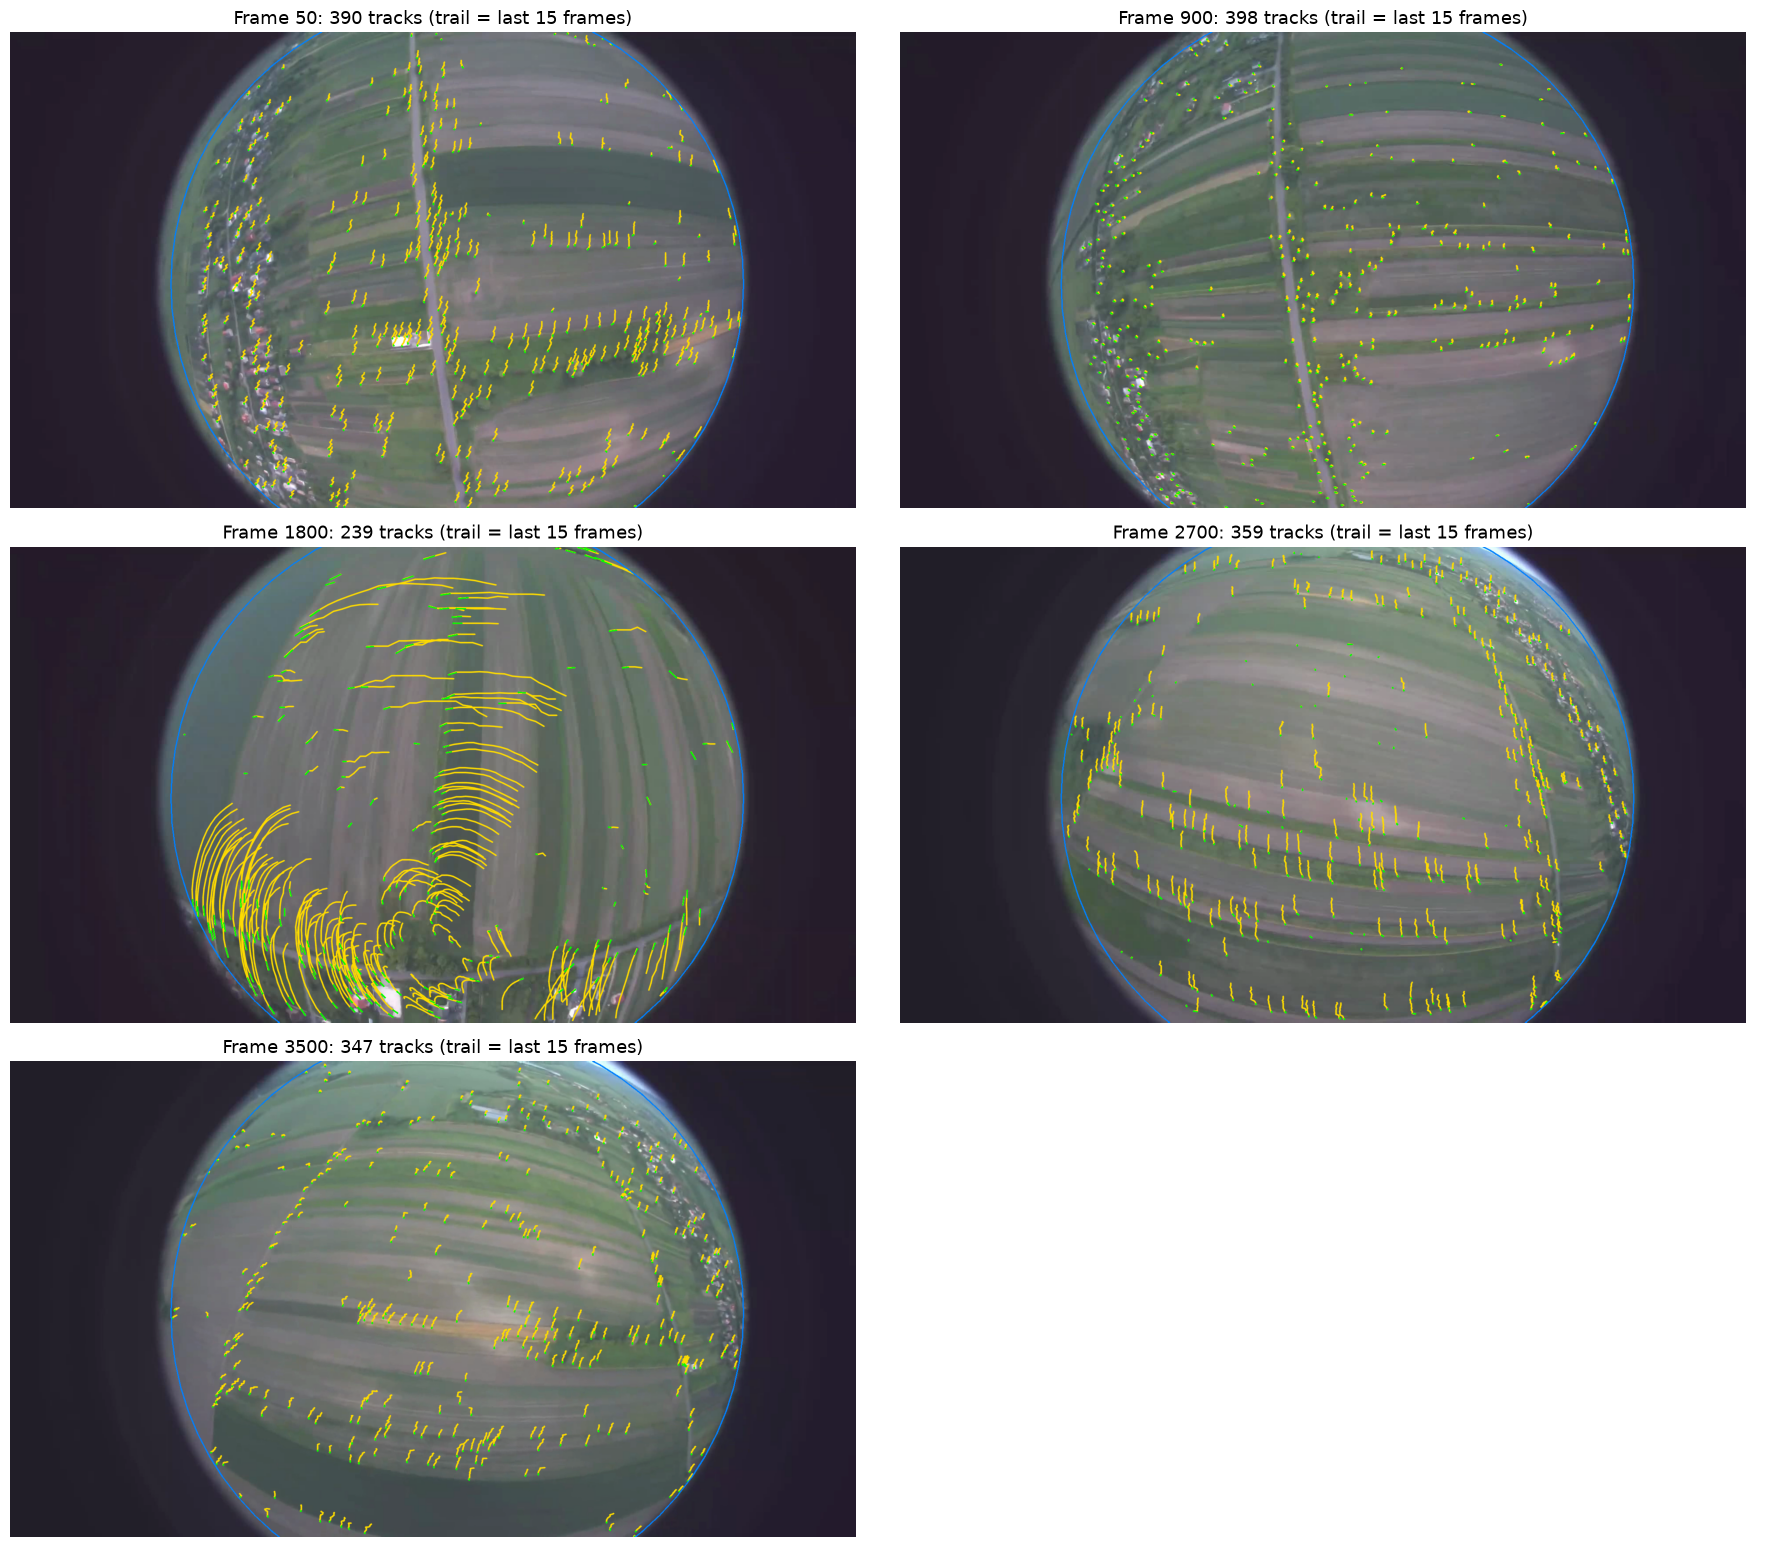

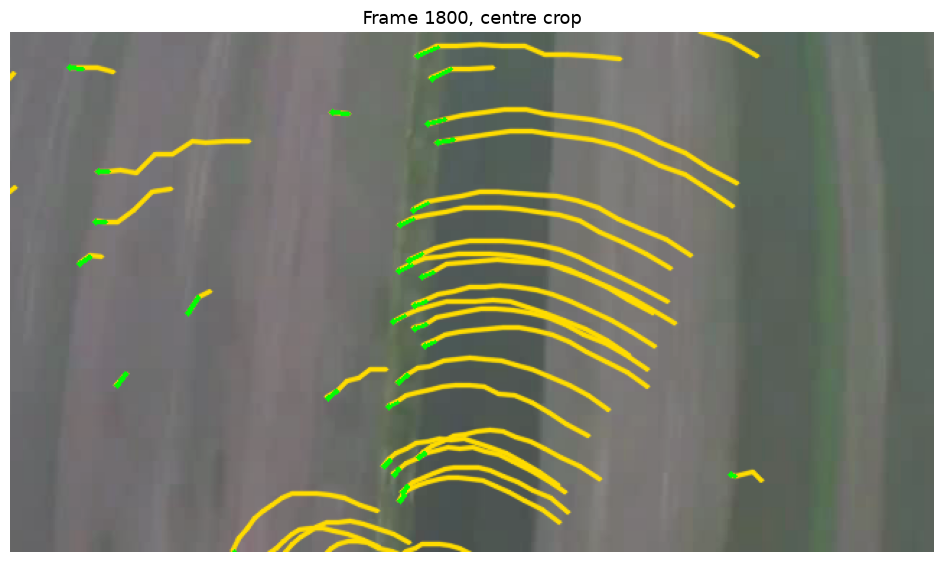

In [18]:
# visual sanity check
snap_keys = sorted(snapshots)
n_cols = 2
n_rows = int(np.ceil(len(snap_keys) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 5.2 * n_rows))
axes = np.atleast_1d(axes).ravel()
for ax, fk in zip(axes, snap_keys):
    ax.imshow(cv.cvtColor(snapshots[fk], cv.COLOR_BGR2RGB))
    ax.set_title(f"Frame {fk}: {stats['tracked'][fk - 1]} tracks (trail = last {TRAIL_LEN} frames)")
    ax.axis("off")
for ax in axes[len(snap_keys):]:
    ax.axis("off")
plt.tight_layout()
plt.show()


fk = snap_keys[len(snap_keys) // 2]
x0, y0 = int(K[0, 2]) - 320, int(K[1, 2]) - 180
plt.figure(figsize=(12, 6.75))
plt.imshow(cv.cvtColor(snapshots[fk][y0:y0 + 360, x0:x0 + 640], cv.COLOR_BGR2RGB))
plt.title(f"Frame {fk}, centre crop")
plt.axis("off")
plt.show()

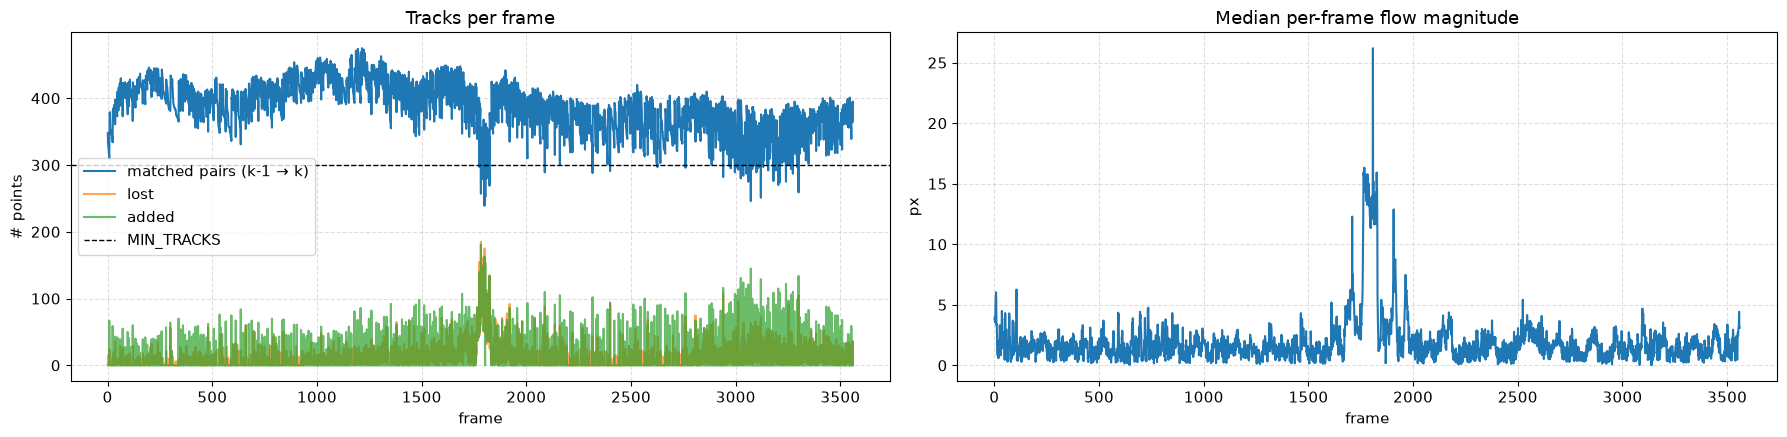

Pairs: 3560
Matches per pair: mean 387, min 239, max 475
Median flow per frame: 1.48 px
Lost per frame: mean 10.3; top-ups on 745 frames


In [19]:
# --- Tracking statistics ---
fig, axes = plt.subplots(1, 2, figsize=(18, 4.5))
axes[0].plot(stats["frame"], stats["tracked"], label="matched pairs (k-1 → k)")
axes[0].plot(stats["frame"], stats["lost"], label="lost", alpha=0.7)
axes[0].plot(stats["frame"], stats["added"], label="added", alpha=0.7)
axes[0].axhline(MIN_TRACKS, color="k", ls="--", lw=1, label="MIN_TRACKS")
axes[0].set_xlabel("frame")
axes[0].set_ylabel("# points")
axes[0].set_title("Tracks per frame")
axes[0].legend()
axes[0].grid(True, ls="--", alpha=0.4)

axes[1].plot(stats["frame"], stats["median_flow"])
axes[1].set_xlabel("frame")
axes[1].set_ylabel("px")
axes[1].set_title("Median per-frame flow magnitude")
axes[1].grid(True, ls="--", alpha=0.4)
plt.tight_layout()
plt.show()

n_matches = np.array([len(p["pts_prev"]) for p in track_pairs])
print(f"Pairs: {len(track_pairs)}")
print(f"Matches per pair: mean {n_matches.mean():.0f}, min {n_matches.min()}, max {n_matches.max()}")
print(f"Median flow per frame: {np.nanmedian(stats['median_flow']):.2f} px")
print(f"Lost per frame: mean {stats['lost'].mean():.1f}; top-ups on {np.count_nonzero(stats['added'])} frames")

## camera motion

The camera looks almost straight down at flat ground, so two views of the ground are related by a homography $H = R + t\,n^T/d$, where $d$ is the camera height above the ground.

1. Accumulate tracks from a keyframe until the median displacement exceeds `MIN_PARALLAX` px
2. convert both point sets to undistorted normalized coordinates and keep only points within `MAX_ANGLE` of the optical axis; further out, the undistorted coordinates blow up and amplify tracking noise
3. Fit $H$ with RANSAC
4. `decomposeHomographyMat` gives up to 4 candidates $(R, t, n)$. Keep those where all inliers lie in front of both cameras, then the one whose plane normal is closest to the optical axis.
5. Chain the motions: $t$ comes in units of $d$, so each step is scaled by the current height estimate, which is updated from $n$ and the step itself
6. Frames between keyframes get linearly interpolated positions, so there is a pose for every frame. The evaluation aligns VO to GT on the first 500 poses, which is meant as the first 500 frames

In [20]:
MAX_ANGLE = 60
RANSAC_PX = 1.5
MIN_PARALLAX = 15
MAX_GAP = 30
MIN_INLIERS = 30

In [21]:
class PlaneOdometry:

    def __init__(self, K):
        self.f = K[0, 0]
        self.max_tan = np.tan(np.radians(MAX_ANGLE))
        self.R = np.eye(3)
        self.c = np.zeros(3)
        self.height = 1.0
        self.positions = [self.c.copy()]
        self.frame_indices, self.inliers = [], []
        self.kf_idx = 0
        self.kf_pts = {}
        self.failed = 0
        self.all_frames, self.all_times = [], []

    def estimate(self, pts_a, pts_b):
        if len(pts_a) < MIN_INLIERS:
            return None
        na = undistort_to_normalized(pts_a)
        nb = undistort_to_normalized(pts_b)
        keep = (np.linalg.norm(na, axis=1) < self.max_tan) & (np.linalg.norm(nb, axis=1) < self.max_tan)
        na, nb = na[keep], nb[keep]
        if len(na) < MIN_INLIERS:
            return None
        H, mask = cv.findHomography(na, nb, cv.RANSAC, RANSAC_PX / self.f)
        if H is None or mask.sum() < MIN_INLIERS:
            return None
        mask = mask.ravel().astype(bool)
        _, Rs, ts, ns = cv.decomposeHomographyMat(H, np.eye(3))
        visible = cv.filterHomographyDecompByVisibleRefpoints(Rs, ns, na[mask].reshape(-1, 1, 2).astype(np.float32), nb[mask].reshape(-1, 1, 2).astype(np.float32))
        if visible is None or len(visible) == 0:
            return None
        best = max(visible.ravel(), key=lambda i: ns[i][2, 0])
        return Rs[best], ts[best].ravel(), ns[best].ravel(), int(mask.sum())

    def step(self, pair):
        self.all_frames.append(pair["curr_idx"])
        self.all_times.append(pair["timestamp"])
        ids = pair["track_ids"].tolist()
        if pair["prev_idx"] == self.kf_idx:
            for tid, p in zip(ids, pair["pts_prev"]):
                self.kf_pts.setdefault(tid, p)
        cur = dict(zip(ids, pair["pts_curr"]))
        common = [tid for tid in cur if tid in self.kf_pts]
        pts_a = np.array([self.kf_pts[tid] for tid in common]).reshape(-1, 2)
        pts_b = np.array([cur[tid] for tid in common]).reshape(-1, 2)
        flow = np.median(np.linalg.norm(pts_b - pts_a, axis=1)) if common else 0.0
        if flow < MIN_PARALLAX and pair["curr_idx"] - self.kf_idx < MAX_GAP:
            return

        res = self.estimate(pts_a, pts_b)
        n_in = 0
        if res is None:
            self.failed += 1
        else:
            R, t, n, n_in = res
            move = -R.T @ t
            self.c = self.c + self.height * (self.R @ move)
            self.height *= 1 - n @ move
            self.R = self.R @ R.T

        self.positions.append(self.c.copy())
        self.frame_indices.append(pair["curr_idx"])
        self.inliers.append(n_in)
        self.kf_idx = pair["curr_idx"]
        self.kf_pts = cur

    def result(self):
        kf = [0] + self.frame_indices
        pos = np.array(self.positions)
        frames = np.array([f for f in self.all_frames if f <= kf[-1]])
        xyz = np.column_stack([np.interp(frames, kf, pos[:, i]) for i in range(3)])
        inliers = np.array(self.inliers)[np.searchsorted(kf, frames) - 1]
        times = np.array(self.all_times)[:len(frames)]
        return TrajectoryResult(timestamps=times.tolist(), positions=np.vstack([pos[:1], xyz]), inliers=inliers.tolist(), frame_indices=frames.tolist())

In [22]:
odo = PlaneOdometry(K)
for pair in tqdm(track_pairs, desc="Pose", unit="pair"):
    odo.step(pair)
traj_result = odo.result()

gaps = np.diff([0] + odo.frame_indices)
print(f"Keyframes: {len(odo.frame_indices)}, mean gap {gaps.mean():.1f} frames, failed estimates: {odo.failed}")
print(f"Inliers per keyframe: median {np.median(odo.inliers):.0f}, min {np.min(odo.inliers)}")
print(f"Poses: {len(traj_result.frame_indices)} (keyframes plus interpolated frames in between)")
print(f"Final height: {odo.height:.3f} of the starting height")

Pose:   0%|          | 0/3560 [00:00<?, ?pair/s]

Keyframes: 327, mean gap 10.9 frames, failed estimates: 27
Inliers per keyframe: median 151, min 0
Poses: 3556 (keyframes plus interpolated frames in between)
Final height: 0.868 of the starting height


## Step 3: evaluation, diagnosis, parameter experiments, overlay video

Steps 1–2 hand over `track_pairs` and `PlaneOdometry`. This section:

1. puts the trajectory into a map frame the GT can be compared with (3.1),
2. finds where and why the trajectory breaks (3.2) and fixes the main failure (3.3),
3. sweeps the parameters of both stages and records what improves or breaks (3.4),
4. builds the final `traj_result` and the overlay video (3.5).

All numbers use the same alignment as `analyze_trajectory`: a 2D similarity fitted on the first 500 poses, then applied to the whole run.

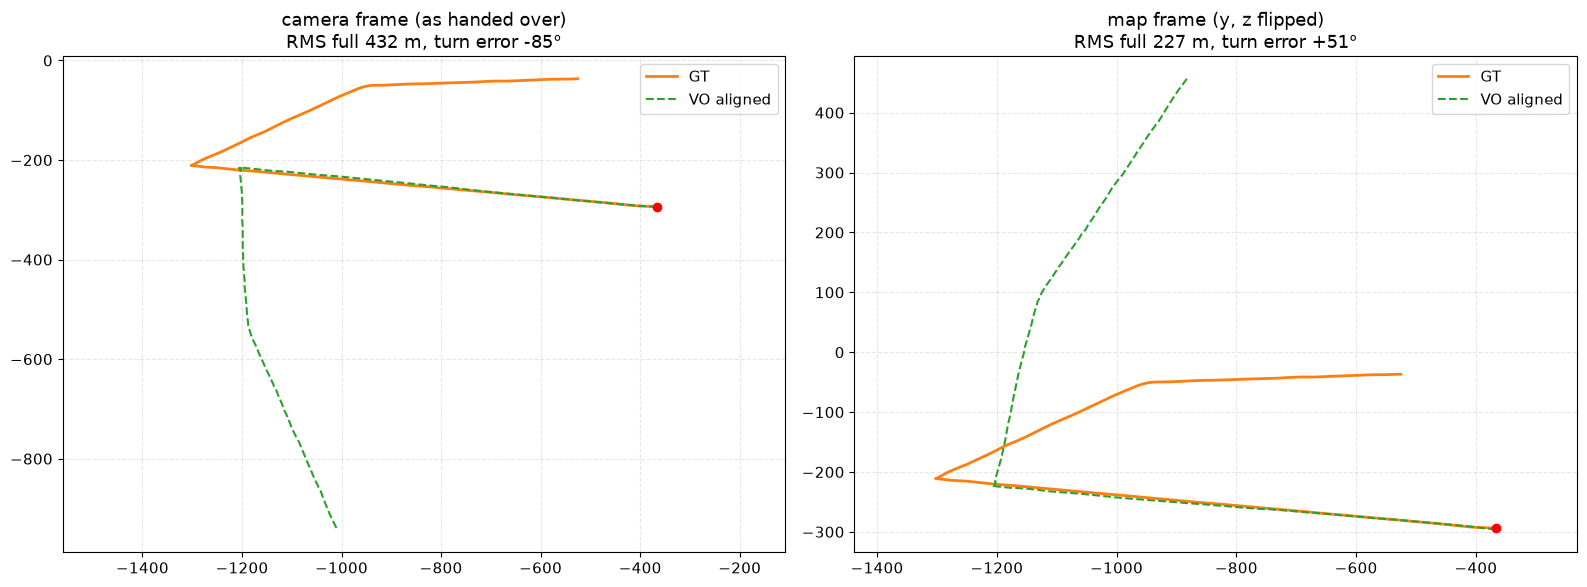

In [ ]:
gt_df = pd.read_csv(GT_PATH).set_index("frame_number")

CAM_TO_MAP = np.diag([1.0, -1.0, -1.0])

def to_map(traj: TrajectoryResult) -> TrajectoryResult:
    return TrajectoryResult(
        timestamps=list(traj.timestamps),
        positions=np.asarray(traj.positions) @ CAM_TO_MAP.T,
        inliers=list(traj.inliers),
        frame_indices=list(traj.frame_indices))

def align_to_gt(traj: TrajectoryResult, calib: int = 500):
    # Same steps as pose_helpers.analyze_trajectory, but returns the arrays instead of printing
    fi, vo, gt = load_and_prepare_data(GT_PATH, np.asarray(traj.frame_indices), np.asarray(traj.positions)[1:, :2])
    s, R2, t2 = align_similarity(vo[:calib], gt[:calib])
    return fi, s * vo @ R2.T + t2, gt

# Segments of the flight, read off the GT: a straight leg, a sharp right turn, then a second leg.
LEG1, TURN, LEG2 = (100, 1700), (1700, 2000), (2000, 3550)

def _direction(xy, fi, a, b):
    i, j = np.searchsorted(fi, [a, b])
    j = min(j, len(fi) - 1)
    d = xy[j] - xy[i]
    return np.degrees(np.arctan2(d[1], d[0]))

def traj_metrics(traj: TrajectoryResult) -> dict:
    fi, vo, gt = align_to_gt(traj)
    err = np.linalg.norm(vo - gt, axis=1)
    turn = lambda xy: (_direction(xy, fi, *LEG2) - _direction(xy, fi, *LEG1) + 180) % 360 - 180
    leg = lambda a, b: (fi >= a) & (fi <= b)
    m1, m2 = leg(*LEG1), leg(*LEG2)
    return {
        "rms_calib_m": np.sqrt(np.mean(err[:500] ** 2)),
        "rms_full_m": np.sqrt(np.mean(err ** 2)),
        "end_err_m": err[-1],
        "turn_err_deg": (turn(vo) - turn(gt) + 180) % 360 - 180,
        "leg1_len_ratio": compute_path_length(vo[m1]) / compute_path_length(gt[m1]),
        "leg2_len_ratio": compute_path_length(vo[m2]) / compute_path_length(gt[m2]),}

raw = traj_result
mapped = to_map(raw)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, tr, name in [(axes[0], raw, "camera frame (as handed over)"), (axes[1], mapped, "map frame (y, z flipped)")]:
    fi, vo, gt = align_to_gt(tr)
    m = traj_metrics(tr)
    ax.plot(gt[:, 0], gt[:, 1], color="tab:orange", lw=2, label="GT")
    ax.plot(vo[:, 0], vo[:, 1], "--", color="tab:green", label="VO aligned")
    ax.plot(*gt[0], "ro")
    ax.set_title(f"{name}\nRMS full {m['rms_full_m']:.0f} m, turn error {m['turn_err_deg']:+.0f}°")
    ax.axis("equal"); ax.grid(True, ls="--", alpha=0.3); ax.legend()
plt.tight_layout()
plt.show()

### 3.1 Camera frame vs map frame

Left: the Step 2 trajectory as handed over. The first 500 poses fit the GT, but the turn goes left instead of right. `align_similarity` only allows proper rotations (it fixes `det R = +1`), so it cannot undo a mirror image. Right: after the 180° rotation about the camera x axis, the turn goes the right way. Every result below is in this map frame.

### 3.2 Where the trajectory breaks

Even in the map frame VO under-turns. `EvalOdometry` below is Person 2's `PlaneOdometry` with bookkeeping added: why each keyframe estimate failed, which tracks were RANSAC inliers (for the overlay video), and the height estimate. With `rot_fallback=False` it computes exactly the same thing as `PlaneOdometry`; the `assert` checks that.

Keyframe outcomes (Step 2 as handed over):
ok                      300
no visible candidate     27


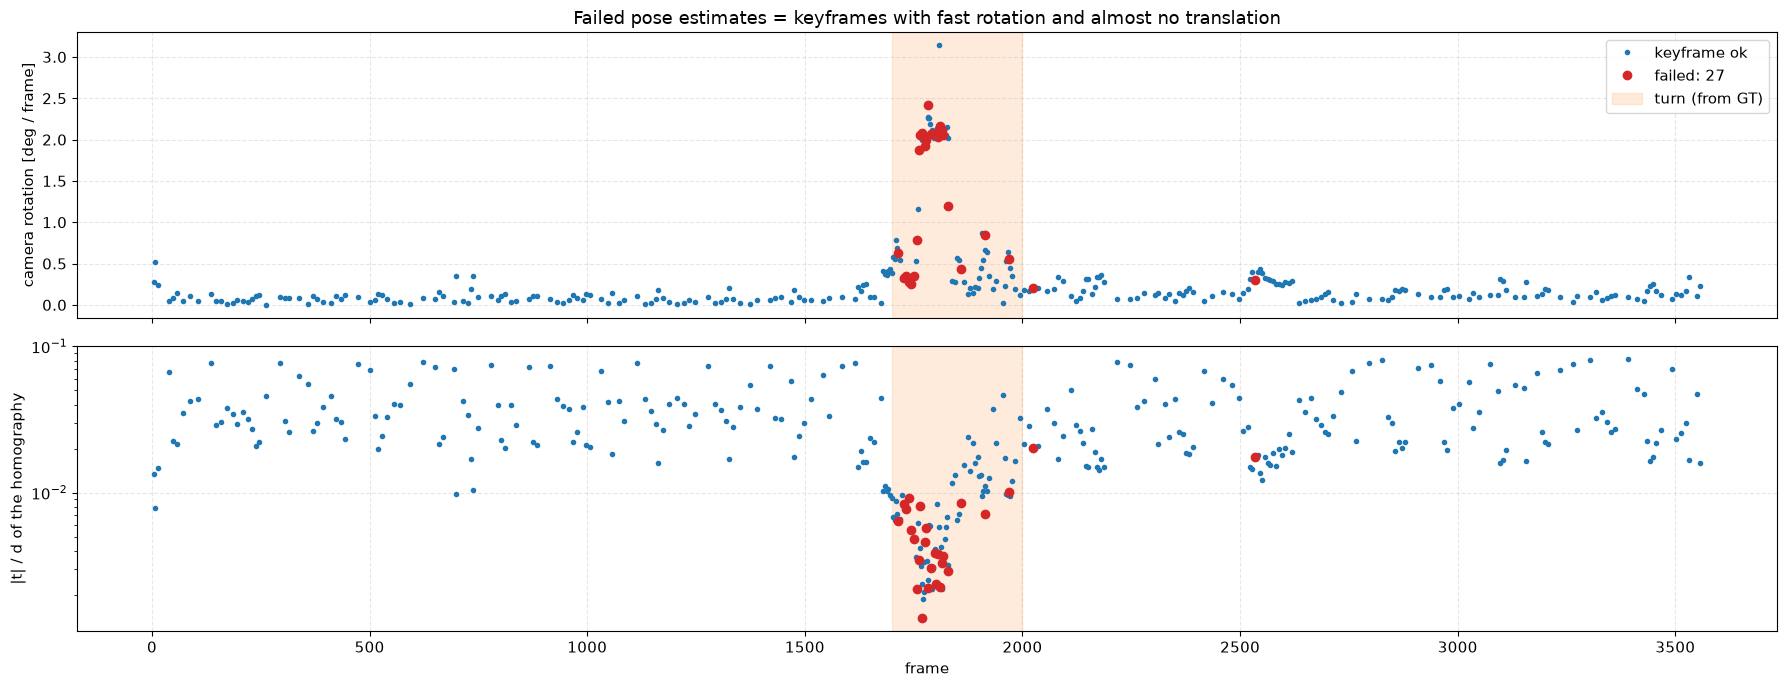

median |t|/d: ok keyframes 0.0257, failed keyframes 0.0046
median gap: ok keyframes 9 frames, failed keyframes 2 frames
25 of 27 failures are inside the turn (frames 1700-2000)


In [32]:
class EvalOdometry(PlaneOdometry):
    def __init__(self, K, rot_fallback=False):
        super().__init__(K)
        self.rot_fallback = rot_fallback
        self.kf_status, self.kf_inlier_ids, self.kf_used_ids = [], [], []
        self.heights = [self.height]
        self.kf_rot_deg, self.kf_tnorm = [], []
        self._mask, self._status, self._rot, self._tn = None, None, np.nan, np.nan

    def estimate(self, pts_a, pts_b):
        self._mask, self._status = None, "too few tracks"
        if len(pts_a) < MIN_INLIERS:
            return None
        na, nb = undistort_to_normalized(pts_a), undistort_to_normalized(pts_b)
        keep = (np.linalg.norm(na, axis=1) < self.max_tan) & (np.linalg.norm(nb, axis=1) < self.max_tan)
        if keep.sum() < MIN_INLIERS:
            self._status = "too few in cone"
            return None
        na, nb = na[keep], nb[keep]
        H, mask = cv.findHomography(na, nb, cv.RANSAC, RANSAC_PX / self.f)
        if H is None or mask.sum() < MIN_INLIERS:
            self._status = "RANSAC failed"
            return None
        inl = mask.ravel().astype(bool)
        self._mask = np.zeros(len(pts_a), bool)
        self._mask[np.flatnonzero(keep)[inl]] = True
        _, Rs, ts, ns = cv.decomposeHomographyMat(H, np.eye(3))
        top = max(range(len(Rs)), key=lambda i: ns[i][2, 0])
        self._rot = np.degrees(np.linalg.norm(cv.Rodrigues(Rs[top])[0]))
        self._tn = float(np.linalg.norm(ts[top]))
        visible = cv.filterHomographyDecompByVisibleRefpoints(
            Rs, ns, na[inl].reshape(-1, 1, 2).astype(np.float32), nb[inl].reshape(-1, 1, 2).astype(np.float32))
        if visible is not None and len(visible):
            best = max(visible.ravel(), key=lambda i: ns[i][2, 0])
            self._status = "ok"
            return Rs[best], ts[best].ravel(), ns[best].ravel(), int(inl.sum())
        if not self.rot_fallback:
            self._status = "no visible candidate"
            return None
        self._status = "rotation only"
        return Rs[top], np.zeros(3), ns[top].ravel(), int(inl.sum())

    def step(self, pair):
        ids = pair["track_ids"].tolist()
        if pair["prev_idx"] == self.kf_idx:
            for tid, p in zip(ids, pair["pts_prev"]):
                self.kf_pts.setdefault(tid, p)
        common = [tid for tid in ids if tid in self.kf_pts]
        n_kf = len(self.frame_indices)
        self._mask, self._status, self._rot, self._tn = None, None, np.nan, np.nan
        super().step(pair)
        if len(self.frame_indices) > n_kf:
            c = np.array(common, dtype=np.int64)
            self.kf_status.append(self._status)
            self.kf_used_ids.append(set(c.tolist()))
            self.kf_inlier_ids.append(set(c[self._mask].tolist()) if self._mask is not None else set())
            self.heights.append(self.height)
            self.kf_rot_deg.append(self._rot)
            self.kf_tnorm.append(self._tn)


def run_odometry(pairs, rot_fallback=False, **params):
    saved = {k: globals()[k] for k in params}
    globals().update(params)
    try:
        o = EvalOdometry(K, rot_fallback=rot_fallback)
        for p in pairs:
            o.step(p)
        return o
    finally:
        globals().update(saved)


base_odo = run_odometry(track_pairs)
assert np.allclose(np.array(base_odo.positions), np.array(odo.positions)), "EvalOdometry must reproduce PlaneOdometry"

kf_frames = np.array(base_odo.frame_indices)
status = np.array(base_odo.kf_status)
print("Keyframe outcomes (Step 2 as handed over):")
print(pd.Series(status).value_counts().to_string())

gaps = np.diff(np.concatenate([[0], kf_frames]))
rot_rate = np.array(base_odo.kf_rot_deg) / gaps
fail = status != "ok"

fig, axes = plt.subplots(2, 1, figsize=(18, 7), sharex=True)
axes[0].plot(kf_frames[~fail], rot_rate[~fail], ".", color="tab:blue", label="keyframe ok")
axes[0].plot(kf_frames[fail], rot_rate[fail], "o", color="tab:red", label=f"failed: {fail.sum()}")
axes[0].set_ylabel("camera rotation [deg / frame]")
axes[0].set_title("Failed pose estimates = keyframes with fast rotation and almost no translation")
axes[1].semilogy(kf_frames[~fail], np.array(base_odo.kf_tnorm)[~fail], ".", color="tab:blue")
axes[1].semilogy(kf_frames[fail], np.array(base_odo.kf_tnorm)[fail], "o", color="tab:red")
axes[1].set_ylabel("|t| / d of the homography")
axes[1].set_xlabel("frame")
for ax in axes:
    ax.axvspan(*TURN, color="tab:orange", alpha=0.15, label="turn (from GT)")
    ax.grid(True, ls="--", alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.show()

print(f"median |t|/d: ok keyframes {np.nanmedian(np.array(base_odo.kf_tnorm)[~fail]):.4f}, "
      f"failed keyframes {np.nanmedian(np.array(base_odo.kf_tnorm)[fail]):.4f}")
print(f"median gap: ok keyframes {np.median(gaps[~fail]):.0f} frames, failed keyframes {np.median(gaps[fail]):.0f} frames")
in_turn = fail & (kf_frames >= TURN[0]) & (kf_frames <= TURN[1])
print(f"{in_turn.sum()} of {fail.sum()} failures are inside the turn (frames {TURN[0]}-{TURN[1]})")

Almost all failures are inside the turn and all have the same cause: **no candidate passes the visibility check**. In the turn the camera rotates about 2° per frame (peaks at 4°; the drone yaws and banks); the overlay at frame 1780 below even shows the horizon. That rotational flow passes `MIN_PARALLAX` within 1–5 frames. In that time the drone moves only 0.5–2.5 m (it flies at ~10 m/s), which is tiny compared with the height (~190 m, judging by the alignment scale). So the translation part of $H = R + t\,n^T/d$ is at noise level (‖t‖/d ≈ 0.001–0.01). With $t \approx 0$ the plane normal is undefined, and `filterHomographyDecompByVisibleRefpoints` rejects all four $(R, t, n)$ candidates. `PlaneOdometry.step` then leaves the pose unchanged and moves on to the next keyframe, so the **rotation of those frames is lost**. That is the missing ~60° of the turn, and everything after it inherits the wrong heading.

### 3.3 Fix: keep the rotation when the translation is unobservable

When every candidate fails the visibility check, the rotation is still well defined: as $t \to 0$ all four candidates share almost the same $R$. So `rot_fallback=True` applies that $R$ with zero translation. The cost is the small translation of that keyframe interval (the drone moves at most a few cm × d there).

Keyframe outcomes with the fallback:
ok               300
rotation only     27


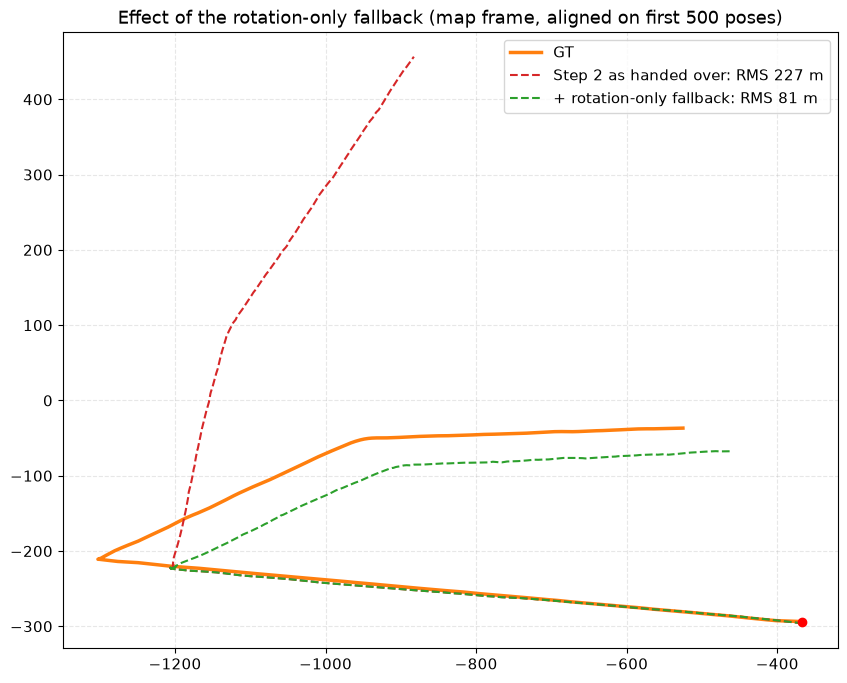

,rms_calib_m,rms_full_m,end_err_m,turn_err_deg,leg1_len_ratio,leg2_len_ratio
variant,,,,,,
Step 2 as handed over,0.85,227.06,609.19,50.58,0.97,0.86
+ rotation-only fallback,0.85,81.14,73.18,-2.43,0.97,0.87


In [33]:
fb_odo = run_odometry(track_pairs, rot_fallback=True)
print("Keyframe outcomes with the fallback:")
print(pd.Series(fb_odo.kf_status).value_counts().to_string())

variants = {"Step 2 as handed over": base_odo, "+ rotation-only fallback": fb_odo}
rows = []
fig, ax = plt.subplots(figsize=(10, 8))
fi, _, gt = align_to_gt(to_map(base_odo.result()))
ax.plot(gt[:, 0], gt[:, 1], color="tab:orange", lw=2.5, label="GT")
for (name, o), c in zip(variants.items(), ["tab:red", "tab:green"]):
    tr = to_map(o.result())
    _, vo, _ = align_to_gt(tr)
    m = traj_metrics(tr)
    rows.append({"variant": name, **m})
    ax.plot(vo[:, 0], vo[:, 1], "--", color=c, label=f"{name}: RMS {m['rms_full_m']:.0f} m")
ax.plot(*gt[0], "ro")
ax.axis("equal"); ax.grid(True, ls="--", alpha=0.3); ax.legend()
ax.set_title("Effect of the rotation-only fallback (map frame, aligned on first 500 poses)")
plt.show()
pd.DataFrame(rows).set_index("variant").round(2)

### 3.4 Parameter experiments

All sweeps use the fallback, because without it the final error depends mostly on how many turn keyframes happen to fail. That makes it jump unpredictably with any parameter change. One parameter is changed at a time; everything else stays at the Step 1/2 defaults.

- **Tracking (Step 1)**, which needs a full re-track (~1 min per run): number of points (`MAX_PER_CELL`, with `MIN_TRACKS` scaled in proportion) and the LK window size.
- **Pose (Step 2)**, which reuses the default `track_pairs` and takes seconds: RANSAC reprojection threshold, `MAX_ANGLE`, `MIN_PARALLAX`.
- **Noise floor:** first, `MIN_PARALLAX` is nudged by ±1–2 px, which should not matter physically. The spread of the error over these runs is the "noise" of a single-trajectory metric. A change smaller than that spread is not evidence of anything.

Results are cached in `experiments/sweep_results.csv`. Delete the file, or set `RERUN_SWEEP = True`, to recompute (~8–10 min).

In [34]:
SWEEP_DIR = Path("experiments")
SWEEP_CSV = SWEEP_DIR / "sweep_results.csv"
RERUN_SWEEP = False


def track_video(max_per_cell=None, win=None):
    global CELL_TARGET, MIN_TRACKS, LK_PARAMS
    saved = (CELL_TARGET, MIN_TRACKS, LK_PARAMS)
    if max_per_cell is not None:
        CELL_TARGET = np.ceil(max_per_cell * cell_valid_frac).astype(int)
        MIN_TRACKS = int(round(MIN_TRACKS * max_per_cell / MAX_PER_CELL))
    if win is not None:
        LK_PARAMS = {**LK_PARAMS, "winSize": (win, win)}
    try:
        cap = cv.VideoCapture(str(VIDEO_PATH))
        ok, frame = cap.read()
        prev_gray = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)
        pts = detect_features(prev_gray, np.empty((0, 2), np.float32))
        ids, next_id = np.arange(len(pts)), len(pts)
        pairs, k, lost = [], 0, 0
        while True:
            ok, frame = cap.read()
            if not ok:
                break
            k += 1
            gray = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)
            p1, keep = track_lk(prev_gray, gray, pts)
            lost += int((~keep).sum())
            pairs.append(dict(prev_idx=k - 1, curr_idx=k, timestamp=k / fps,
                              pts_prev=pts[keep].astype(np.float32), pts_curr=p1[keep].astype(np.float32),
                              track_ids=ids[keep]))
            pts, ids = p1[keep], ids[keep]
            if needs_topup(pts):
                new = detect_features(gray, pts)
                if len(new):
                    pts = np.vstack([pts, new])
                    ids = np.concatenate([ids, np.arange(next_id, next_id + len(new))])
                    next_id += len(new)
            prev_gray = gray
        cap.release()
        return pairs, lost / k
    finally:
        CELL_TARGET, MIN_TRACKS, LK_PARAMS = saved


def summarize(group, value, o, pairs, extra=None):
    st = pd.Series(o.kf_status)
    return {
        "group": group, "value": value,
        **traj_metrics(to_map(o.result())),
        "matches_per_pair": np.mean([len(p["pts_prev"]) for p in pairs]),
        "median_inliers": float(np.median([n for n in o.inliers if n > 0])),
        "keyframes": len(o.frame_indices),
        "rot_only_kf": int((st == "rotation only").sum()),
        "failed_kf": int((~st.isin(["ok", "rotation only"])).sum()),
        **(extra or {})}


if SWEEP_CSV.exists() and not RERUN_SWEEP:
    sweep = pd.read_csv(SWEEP_CSV)
    print(f"Loaded cached sweep from {SWEEP_CSV} ({len(sweep)} runs)")
else:
    import time
    rows = []
    default_lost = float(np.mean(stats["lost"]))
    for r in [1.5, 3.0, 6.0, 10.0, 15.0]:
        for mp in [13, 14, 15, 16, 17]:
            o = run_odometry(track_pairs, True, RANSAC_PX=r, MIN_PARALLAX=mp)
            rows.append(summarize("RANSAC_PX x MIN_PARALLAX±2", r, o, track_pairs, {"min_parallax": mp}))
    for r in [0.5, 1.0, 1.5, 3.0, 6.0, 10.0, 15.0]:
        rows.append(summarize("RANSAC_PX", r, run_odometry(track_pairs, True, RANSAC_PX=r), track_pairs))
    for a in [30, 45, 60, 75]:
        rows.append(summarize("MAX_ANGLE", a, run_odometry(track_pairs, True, MAX_ANGLE=a), track_pairs))
    for mp in [5, 15, 30, 60]:
        rows.append(summarize("MIN_PARALLAX", mp, run_odometry(track_pairs, True, MIN_PARALLAX=mp), track_pairs))
    track_runs = [("MAX_PER_CELL", v, dict(max_per_cell=v)) for v in [4, 8, 15, 30]] + \
                 [("LK winSize", v, dict(win=v)) for v in [7, 11, 21, 31, 51]]
    for group, v, kw in tqdm(track_runs, desc="Tracking sweep"):
        if (group == "MAX_PER_CELL" and v == MAX_PER_CELL) or (group == "LK winSize" and v == LK_PARAMS["winSize"][0]):
            pairs, lost, secs = track_pairs, default_lost, np.nan       # the default run from Step 1
        else:
            t0 = time.time()
            pairs, lost = track_video(**kw)
            secs = time.time() - t0
        o = run_odometry(pairs, True)
        rows.append(summarize(group, v, o, pairs, {"lost_per_frame": lost, "track_time_s": secs}))
    sweep = pd.DataFrame(rows)
    SWEEP_DIR.mkdir(exist_ok=True)
    sweep.to_csv(SWEEP_CSV, index=False)

main = sweep[sweep["group"] != "RANSAC_PX x MIN_PARALLAX±2"]
cols = ["rms_calib_m", "rms_full_m", "end_err_m", "turn_err_deg", "leg1_len_ratio", "leg2_len_ratio",
        "matches_per_pair", "median_inliers", "keyframes", "rot_only_kf", "failed_kf", "lost_per_frame"]
main.set_index(["group", "value"])[cols].round(2)

Loaded cached sweep from experiments/sweep_results.csv (49 runs)


rms_calib_m  rms_full_m  end_err_m  turn_err_deg  \
group        value                                                     
RANSAC_PX    0.5           0.86       58.54      84.81          2.76   
             1.0           1.04       76.61      73.42         -0.61   
             1.5           0.82       94.64      89.30         -2.30   
             3.0           0.95       70.17      50.97         -3.39   
             6.0           0.92       53.12      47.86         -1.80   
             10.0          0.87       61.12      99.44          0.56   
             15.0          0.89       33.14      50.79          3.51   
MAX_ANGLE    30.0          3.65      167.93     456.01         11.64   
             45.0          1.39       63.52       9.00         -0.34   
             60.0          0.82       94.64      89.30         -2.30   
             75.0          0.79       74.72      61.71         -2.58   
MIN_PARALLAX 5.0           0.85       78.29      69.95         -1.00   
             15.0          0.82       94.64      89.30         -2.30   
             30.0          0.83      112.41     166.73         -2.12   
             60.0          0.83      104.28     153.43         -3.32   
MAX_PER_CELL 4.0           0.81       75.98      91.34         -2.28   
             8.0           0.99       76.53      77.85         -1.68   
             15.0          0.82       94.64      89.30         -2.30   
             30.0          0.93       81.44      78.65         -1.87   
LK winSize   7.0           1.00      111.82     163.85         -2.33   
             11.0          1.00       84.91      86.92         -1.75   
             21.0          0.82       94.64      89.30         -2.30   
             31.0          0.72       80.29     101.70         -3.29   
             51.0          0.94       92.12     104.59         -2.74   

                    leg1_len_ratio  leg2_len_ratio  matches_per_pair  \
group        value                                                     
RANSAC_PX    0.5              0.97            0.69            384.48   
             1.0              0.97            0.90            384.48   
             1.5              0.94            0.87            384.48   
             3.0              0.97            0.82            384.48   
             6.0              1.02            0.92            384.48   
             10.0             1.03            1.01            384.48   
             15.0             1.03            0.91            384.48   
MAX_ANGLE    30.0             1.07            0.40            384.48   
             45.0             0.98            0.84            384.48   
             60.0             0.94            0.87            384.48   
             75.0             0.97            0.87            384.48   
MIN_PARALLAX 5.0              0.93            0.72            384.48   
             15.0             0.94            0.87            384.48   
             30.0             0.97            1.00            384.48   
             60.0             0.97            0.98            384.48   
MAX_PER_CELL 4.0              0.98            0.93            138.08   
             8.0              0.99            0.91            236.64   
             15.0             0.94            0.87            384.48   
             30.0             0.97            0.89            678.44   
LK winSize   7.0              0.96            0.99            352.56   
             11.0             0.96            0.90            367.66   
             21.0             0.94            0.87            384.48   
             31.0             1.00            0.94            396.04   
             51.0             0.96            0.91            413.54   

                    median_inliers  keyframes  rot_only_kf  failed_kf  \
group        value                                                      
RANSAC_PX    0.5              70.0        331           24         20   
             1.0             139.0        331          

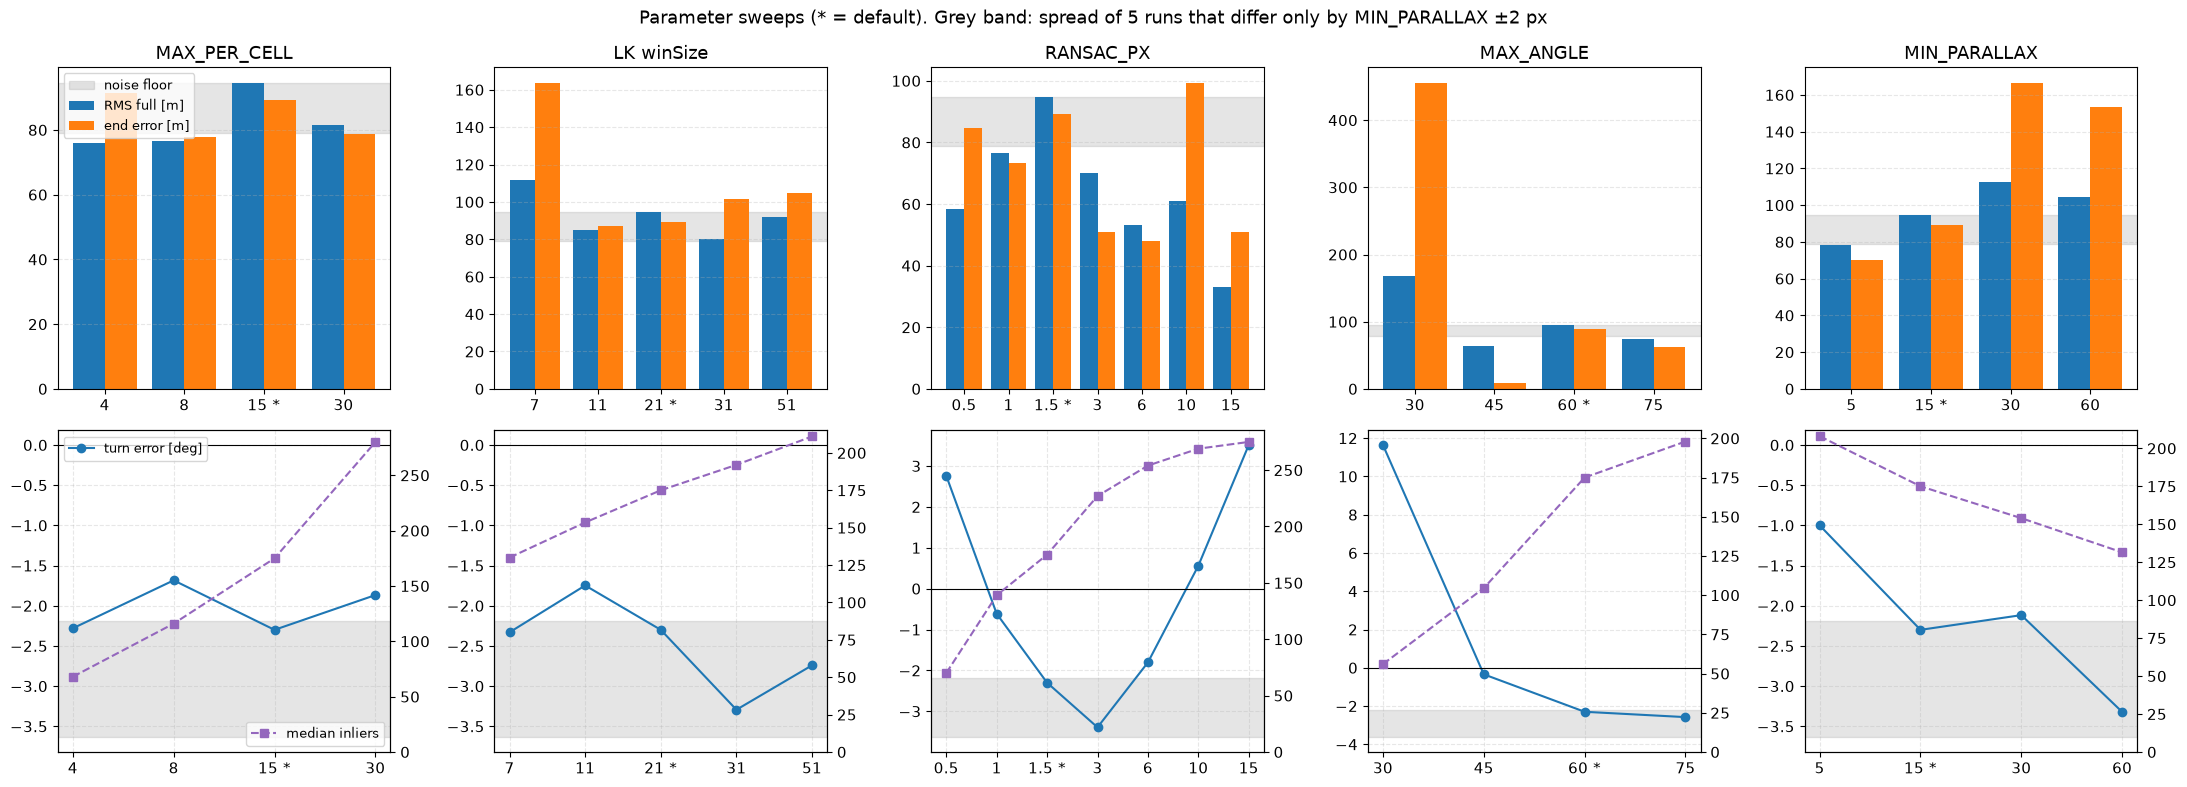

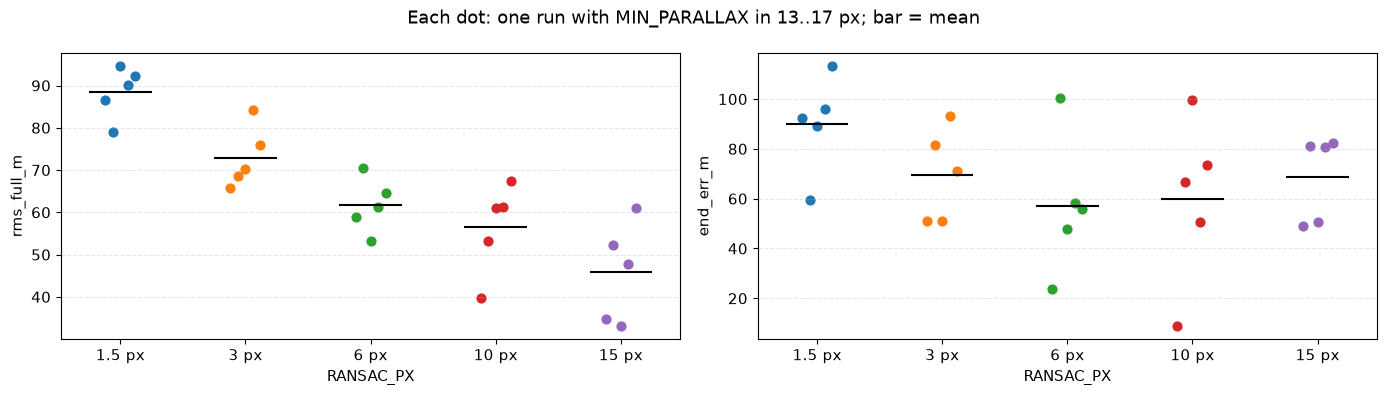

      rms_full_m             end_err_m              turn_err_deg            \
            mean   min   max      mean   min    max         mean  min  max   
value                                                                        
1.5         88.5  79.0  94.6      90.1  59.5  113.3         -2.8 -3.6 -2.2   
3.0         72.9  65.7  84.2      69.6  51.0   93.4         -2.7 -4.2 -1.7   
6.0         61.6  53.1  70.6      57.2  23.7  100.3         -1.5 -2.5 -0.6   
10.0        56.5  39.6  67.3      59.8   8.9   99.4         -0.2 -1.3  0.6   
15.0        45.8  33.1  61.1      68.8  49.0   82.2          3.6  0.9  6.1   

      median_inliers                
                mean    min    max  
value                               
1.5            177.0  173.0  184.0  
3.0            224.6  218.0  229.0  
6.0            255.2  251.0  261.0  
10.0           269.0  265.0  273.0  
15.0           275.4  271.0  280.0  


In [35]:
robust = sweep[sweep["group"] == "RANSAC_PX x MIN_PARALLAX±2"]
noise = robust[robust["value"] == RANSAC_PX]          # default config, MIN_PARALLAX 13..17
groups = ["MAX_PER_CELL", "LK winSize", "RANSAC_PX", "MAX_ANGLE", "MIN_PARALLAX"]
defaults = {"MAX_PER_CELL": MAX_PER_CELL, "LK winSize": LK_PARAMS["winSize"][0], "RANSAC_PX": RANSAC_PX,
            "MAX_ANGLE": MAX_ANGLE, "MIN_PARALLAX": MIN_PARALLAX}

fig, axes = plt.subplots(2, len(groups), figsize=(22, 8))
for j, g in enumerate(groups):
    d = sweep[sweep["group"] == g]
    x = np.arange(len(d))
    labels = [f"{v:g}" + (" *" if float(v) == float(defaults[g]) else "") for v in d["value"]]
    ax = axes[0, j]
    ax.axhspan(noise["rms_full_m"].min(), noise["rms_full_m"].max(), color="grey", alpha=0.2, label="noise floor")
    ax.bar(x - 0.2, d["rms_full_m"], 0.4, label="RMS full [m]")
    ax.bar(x + 0.2, d["end_err_m"], 0.4, label="end error [m]")
    ax.set_xticks(x, labels); ax.set_title(g); ax.grid(True, axis="y", ls="--", alpha=0.3)
    if j == 0:
        ax.legend(fontsize=9)
    ax = axes[1, j]
    ax.plot(x, d["turn_err_deg"], "o-", label="turn error [deg]")
    ax.axhspan(noise["turn_err_deg"].min(), noise["turn_err_deg"].max(), color="grey", alpha=0.2)
    ax.axhline(0, color="k", lw=0.8)
    ax3 = ax.twinx()
    ax3.plot(x, d["median_inliers"], "s--", color="tab:purple", label="median inliers")
    ax3.set_ylim(bottom=0)
    ax.set_xticks(x, labels); ax.grid(True, ls="--", alpha=0.3)
    if j == 0:
        ax.legend(loc="upper left", fontsize=9); ax3.legend(loc="lower right", fontsize=9)
fig.suptitle("Parameter sweeps (* = default). Grey band: spread of 5 runs that differ only by MIN_PARALLAX ±2 px")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, col in zip(axes, ["rms_full_m", "end_err_m"]):
    for i, (r, d) in enumerate(robust.groupby("value")):
        ax.scatter(np.full(len(d), i) + np.linspace(-0.12, 0.12, len(d)), d[col], s=40)
        ax.hlines(d[col].mean(), i - 0.25, i + 0.25, color="k")
    ax.set_xticks(range(robust["value"].nunique()), [f"{v:g} px" for v in sorted(robust["value"].unique())])
    ax.set_xlabel("RANSAC_PX"); ax.set_ylabel(col); ax.grid(True, axis="y", ls="--", alpha=0.3)
fig.suptitle("Each dot: one run with MIN_PARALLAX in 13..17 px; bar = mean")
plt.tight_layout()
plt.show()
print(robust.groupby("value")[["rms_full_m", "end_err_m", "turn_err_deg", "median_inliers"]].agg(["mean", "min", "max"]).round(1))

The bars show where a parameter breaks the trajectory. Differences inside the grey band are noise. Below, the aligned trajectories of the pose-step sweeps (cheap to re-run) show how each setting fails, not just how much.


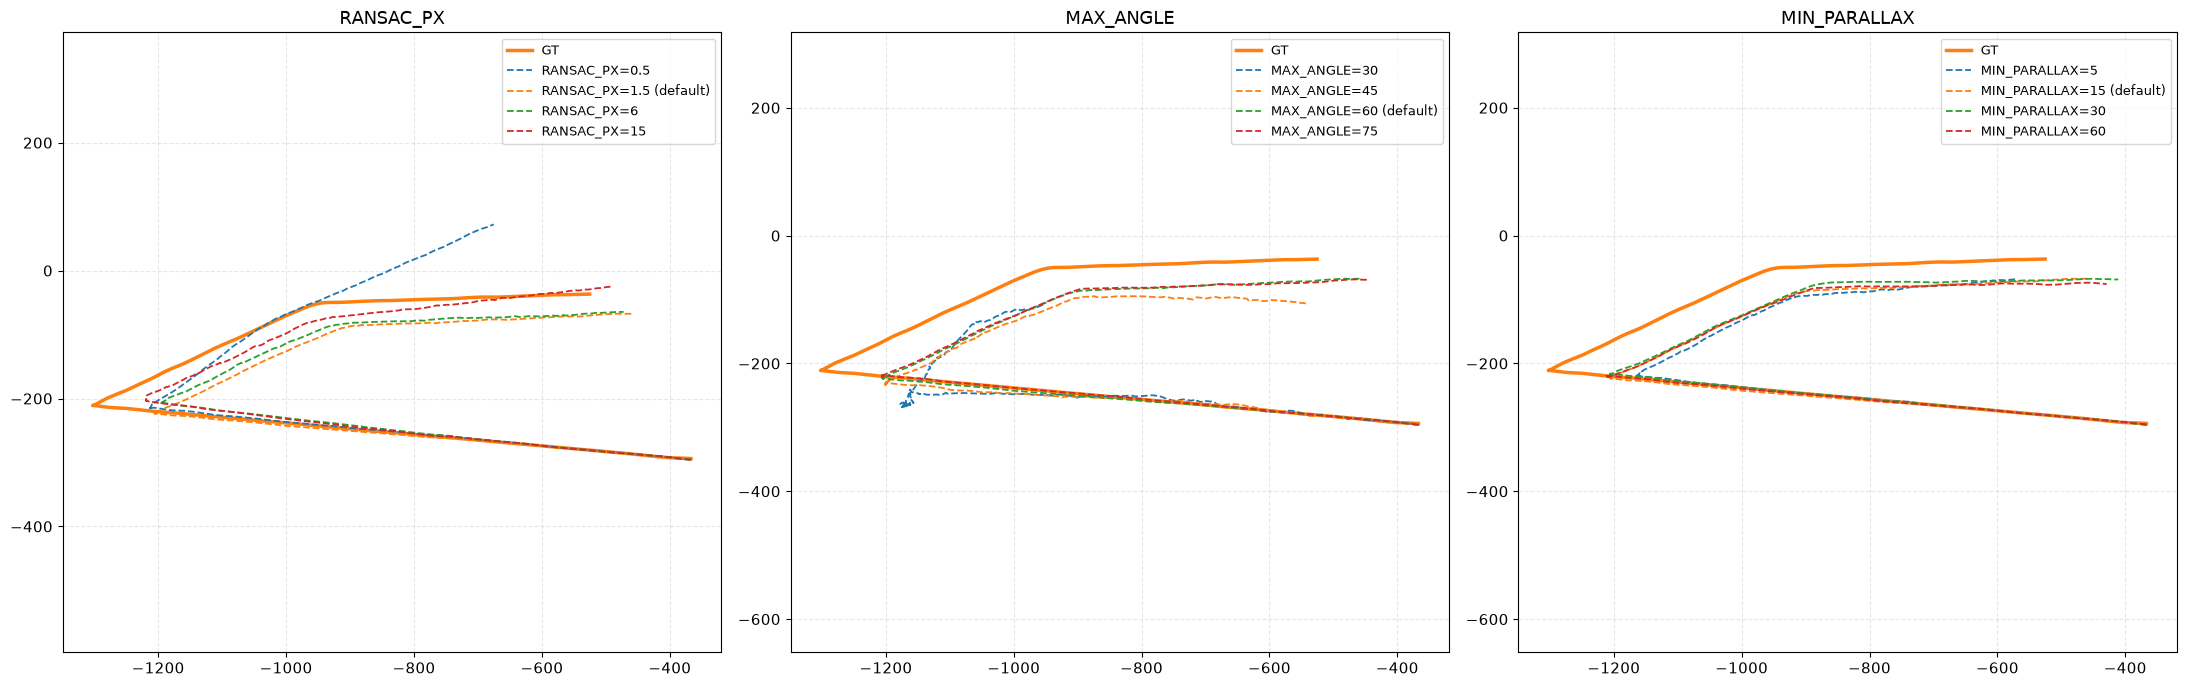

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(22, 7))
_, _, gt = align_to_gt(to_map(fb_odo.result()))
for ax, (g, settings) in zip(axes, [("RANSAC_PX", [0.5, 1.5, 6.0, 15.0]), ("MAX_ANGLE", [30, 45, 60, 75]),
                                     ("MIN_PARALLAX", [5, 15, 30, 60])]):
    ax.plot(gt[:, 0], gt[:, 1], color="tab:orange", lw=2.5, label="GT")
    for v in settings:
        tr = to_map(run_odometry(track_pairs, True, **{g: v}).result())
        _, vo, _ = align_to_gt(tr)
        ax.plot(vo[:, 0], vo[:, 1], "--", lw=1.3, label=f"{g}={v:g}" + (" (default)" if v == defaults[g] else ""))
    ax.axis("equal"); ax.grid(True, ls="--", alpha=0.3); ax.legend(fontsize=9); ax.set_title(g)
plt.tight_layout()
plt.show()

### 3.5 Final trajectory and overlay video

Final configuration: Step 1/2 defaults + rotation-only fallback + `RANSAC_PX = 6` (the only change that beat the noise floor in 3.4, consistently over all five nudged runs, and with a geometric reason behind it; see the summary).

The overlay video has one frame per frame of `recording.mp4`. For frame *k* it draws the step *k−1 → k* of every track. Green: tracks that were RANSAC inliers of the homography for the keyframe interval containing *k*. Red: everything else (RANSAC outliers, points outside the `MAX_ANGLE` cone (blue circle), tracks born inside the interval). The status line shows the keyframe outcome, inlier count and height estimate. It turns orange on rotation-only keyframes and red on failures.

Overlay video:   0%|          | 0/3561 [00:00<?, ?frame/s]

Overlay video: tracks_overlay.mp4 (3561 frames, recording has 3561)


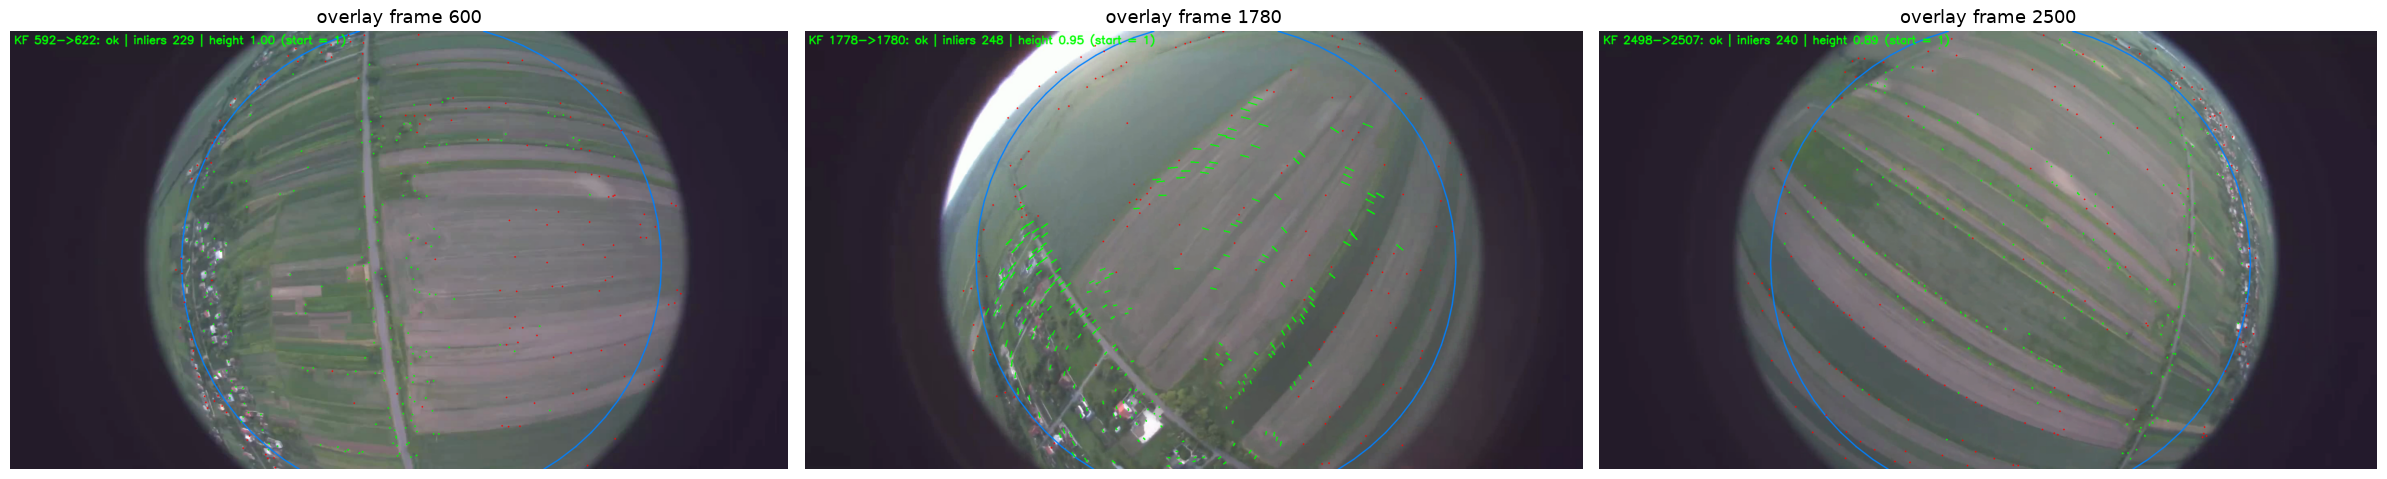

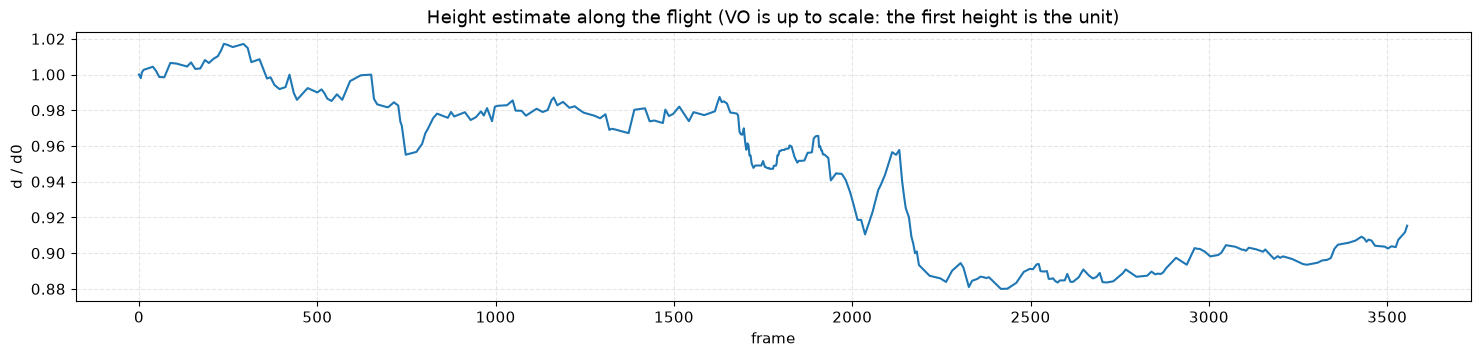

ok               280
rotation only     47
{'rms_calib_m': np.float64(0.84), 'rms_full_m': np.float64(74.56), 'end_err_m': np.float64(59.92), 'turn_err_deg': np.float64(-1.6), 'leg1_len_ratio': 0.96, 'leg2_len_ratio': 0.86}


In [37]:
FINAL_PARAMS = dict(RANSAC_PX=6.0)
final_odo = run_odometry(track_pairs, rot_fallback=True, **FINAL_PARAMS)
traj_result = to_map(final_odo.result())

kf_frames = np.array(final_odo.frame_indices)
kf_status = final_odo.kf_status
cone_r = int(round(cv.fisheye.distortPoints(np.array([[[np.tan(np.radians(MAX_ANGLE)), 0.0]]]), K, D)[0, 0, 0] - K[0, 2]))
STATUS_COLOR = {"ok": (0, 255, 0), "rotation only": (0, 165, 255)}


def overlay_info(k):
    pair = track_pairs[k - 1]
    j = np.searchsorted(kf_frames, k)
    if j >= len(kf_frames):
        return pair, np.zeros(len(pair["track_ids"]), bool), "after last keyframe", (200, 200, 200)
    inl = final_odo.kf_inlier_ids[j]
    mask = np.fromiter((t in inl for t in pair["track_ids"].tolist()), bool, len(pair["track_ids"]))
    st = kf_status[j]
    msg = (f"KF {kf_frames[j - 1] if j else 0}->{kf_frames[j]}: {st} | inliers {final_odo.inliers[j]} "
           f"| height {final_odo.heights[j + 1]:.2f} (start = 1)")
    return pair, mask, msg, STATUS_COLOR.get(st, (0, 0, 255))

cap = cv.VideoCapture(str(VIDEO_PATH))
writer = TrajectoryVideoWriter(OVERLAY_VIDEO_PATH, fps, (IMG_W, IMG_H), draw_thickness=2)
check_frames = {600: None, 1780: None, 2500: None}
for k in tqdm(range(n_frames), desc="Overlay video", unit="frame"):
    ok, frame = cap.read()
    if not ok:
        break
    cv.circle(frame, (int(K[0, 2]), int(K[1, 2])), cone_r, (255, 128, 0), 2, cv.LINE_AA)
    if k == 0:
        writer.write_frame_with_overlay(frame, None, None, None, "first frame", (200, 200, 200))
    else:
        pair, mask, msg, color = overlay_info(k)
        writer.write_frame_with_overlay(frame, pair["pts_prev"], pair["pts_curr"], mask, msg, color)
        if k in check_frames:
            img = frame.copy()
            draw_tracks(img, pair["pts_prev"], pair["pts_curr"], mask, 2)
            cv.putText(img, msg, (10, 30), cv.FONT_HERSHEY_SIMPLEX, 0.9, color, 2, cv.LINE_AA)
            check_frames[k] = img
    writer.increment_frame()
writer.release()
cap.release()

chk = cv.VideoCapture(str(OVERLAY_VIDEO_PATH))
n_written = int(chk.get(cv.CAP_PROP_FRAME_COUNT))
chk.release()
print(f"Overlay video: {OVERLAY_VIDEO_PATH} ({n_written} frames, recording has {n_frames})")
assert n_written == n_frames

fig, axes = plt.subplots(1, 3, figsize=(24, 5))
for ax, (k, img) in zip(axes, check_frames.items()):
    ax.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB)); ax.set_title(f"overlay frame {k}"); ax.axis("off")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(18, 3.5))
ax.plot([0] + list(kf_frames), final_odo.heights, label="estimated height (start = 1)")
ax.set_xlabel("frame"); ax.set_ylabel("d / d0"); ax.grid(True, ls="--", alpha=0.3)
ax.set_title("Height estimate along the flight (VO is up to scale: the first height is the unit)")
plt.show()

print(pd.Series(kf_status).value_counts().to_string())
print({k: round(v, 2) for k, v in traj_metrics(traj_result).items()})

## Evaluation

Do not modify. Checks the result format, plots the trajectory and inliers, renders the trajectory video, and compares against GT.

Recovered 3556 poses


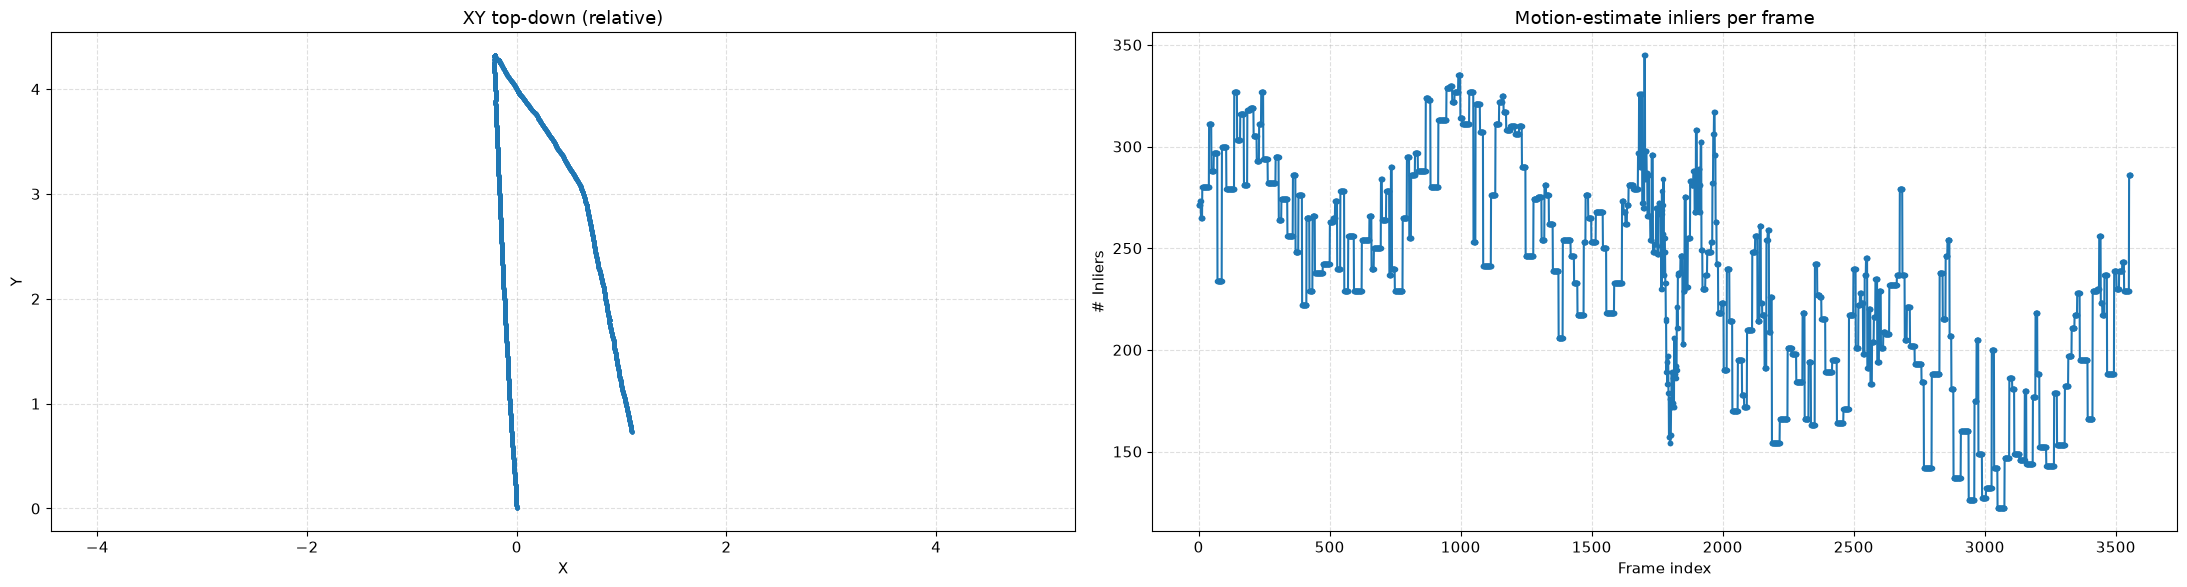

In [38]:
assert isinstance(traj_result, TrajectoryResult), "traj_result must be a TrajectoryResult"
n = len(traj_result.frame_indices)
assert n > 0, "No poses recovered"
assert traj_result.positions.shape[0] == n + 1, "positions must have len(frame_indices) + 1 rows"
assert len(traj_result.inliers) == n and len(traj_result.timestamps) == n, "inliers/timestamps must match frame_indices"
assert OVERLAY_VIDEO_PATH.exists(), f"Overlay video not found: {OVERLAY_VIDEO_PATH}"
print(f"Recovered {n} poses")

plot_trajectory(traj_result)

In [39]:
write_video_with_trajectory(
    OVERLAY_VIDEO_PATH,
    traj_result,
    output_path=TRAJECTORY_VIDEO_PATH,
    stride=5,
)

Writing video with trajectory: 100%|██████████| 712/712 [00:53<00:00, 13.22frame/s]

Output video saved to tracks_with_trajectory.mp4


--- Trajectory Alignment Report ---
Calibrated on first 500 of 3556 overlapping frames.

Similarity Alignment Parameters:
  Scale = 192.8843
  Rotation = 81.06°
  Translation = [-366.05, -295.26] m

Error (Calibration Segment):
  RMS = 0.84 m
  Max = 1.40 m

Error (Full Trajectory):
  RMS = 74.56 m

---------------------------------

Ground truth trajectory length: 1751.67 m
Aligned VO trajectory length:   1594.56 m


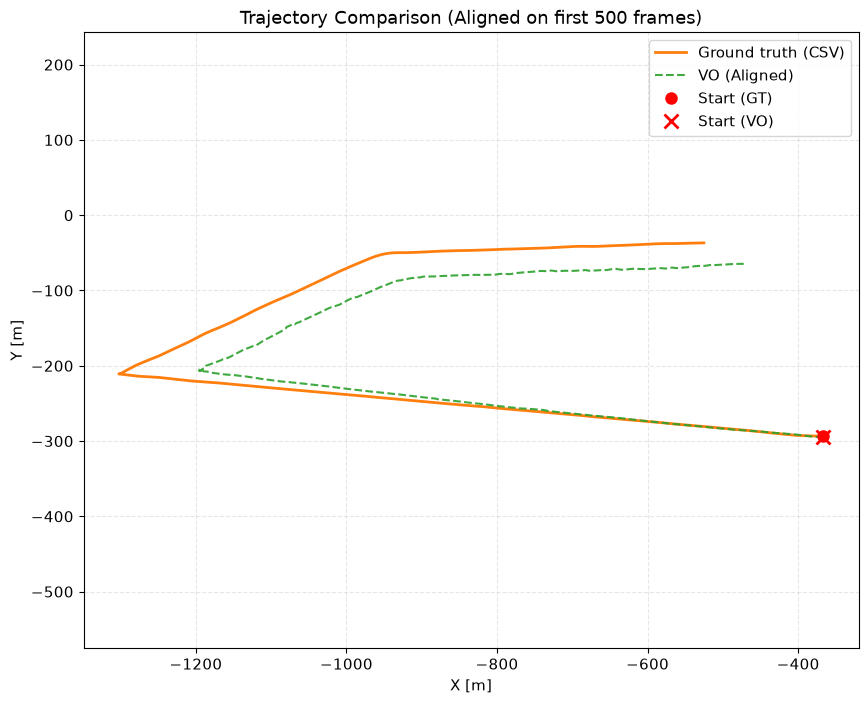

In [40]:
analyze_trajectory(traj_result, GT_PATH)

## Summary

**Implementation choices:** _..._

**Parameter tuning:** _which parameters you tuned, what you tried, and the evidence from your run that justified the final values._

**Trajectory quality and overlay video:** _how close the result is to GT, where it drifts or fails, and why._